In [1]:
import pandas as pd
import re
import matplotlib.pyplot as plt

df = pd.read_csv("fakenews.csv")
df["text"] = df["headline"].fillna("") + " " + df["body_text"].fillna("")

In [2]:
sensational_words = [
    "shocking", "breaking", "unbelievable", "secret",
    "exposed", "bombshell", "urgent", "miracle",
    "shocking", "disaster", "horrifying", "must",
    "exclusive", "warning", "truth", "viral"
]

def find_words(text):
    words = re.findall(r"\b[a-z]+\b", str(text).lower())
    return [word for word in words if word in sensational_words]

df["sensational_words"] = df["text"].apply(find_words)
df["sensational_count"] = df["sensational_words"].apply(len)

print(df[["label", "sensational_words", "sensational_count"]].head())

  label sensational_words  sensational_count
0  Real                []                  0
1  Real                []                  0
2  Fake                []                  0
3  Fake                []                  0
4  Real                []                  0


In [3]:
phrases = [
    "you won't believe",
    "shocking truth",
    "wake up",
    "share before deleted",
    "the hidden truth",
    "100% guaranteed",
    "they don't want you to know"
]

def find_phrases(text):
    text = str(text).lower()
    return [phrase for phrase in phrases if phrase in text]

df["exaggerated_phrases"] = df["text"].apply(find_phrases)

print(df[["label", "exaggerated_phrases"]].head(10))

  label exaggerated_phrases
0  Real                  []
1  Real                  []
2  Fake                  []
3  Fake                  []
4  Real                  []
5  Fake                  []
6  Fake                  []
7  Real                  []
8  Fake                  []
9  Real                  []


In [4]:
comparison = df.groupby("label").agg(
    average_sensational_words=("sensational_count", "mean"),
    total_sensational_words=("sensational_count", "sum")
)

print(comparison)

       average_sensational_words  total_sensational_words
label                                                    
Fake                    0.099099                      110
Real                    0.117967                      130


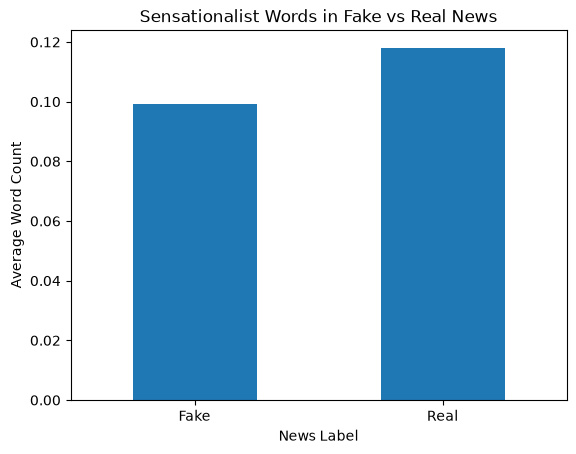

In [5]:
comparison["average_sensational_words"].plot(kind="bar")

plt.title("Sensationalist Words in Fake vs Real News")
plt.xlabel("News Label")
plt.ylabel("Average Word Count")
plt.xticks(rotation=0)
plt.show()

In [7]:
df.to_csv("T38_sensationalist_analysis.csv", index=False)
comparison.to_csv("T38_sensationalist_comparison.csv")
